# code_124 · Sampling, irregular observations and alarm intensity

**Book:** section 24.4. A self-contained forecasting laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_24_GUIDE.md), [run evidence](../CHAPTER_24_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_124).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2724;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
import statsmodels
VERSIONS['statsmodels']=statsmodels.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2724


<a id="observation-process-contract"></a>
 ## A sampled waveform and event arrivals have different targets
 An 8-Hz plus30-Hz vibration signal is observed at100Hz, then reduced to25Hz. Compare naive decimation with actual SciPy polyphase anti-alias filtering on a completed offline window, explicitly acknowledging the zero-phase filter's future context and boundary assumptions. A separate irregular slow signal compares offline linear interpolation with causal previous-observation hold; future changes cannot alter the hold at an earlier query. Then generate sixty independent alarm-recording buildings, each with forty known variable-duration exposure intervals and piecewise-constant covariates. Counts are Poisson(rate×exposure), and ordered event times are drawn uniformly inside each interval conditional on its count. This exactly constructs the stated piecewise Poisson process. Train/development/final buildings40/10/10; rate covariates and interval duration are known before each interval, while event times/counts are outcomes. Complete recording inside each declared window is assumed.


,model,final_process_NLL_per_day,final_any_event_Brier,completed_rescaled_gap_count,rescaled_gap_mean,rescaled_gap_Exp1_KS_statistic,sum_right_censored_tail_hazard
0,Constant rate,0.796220,0.227459,311,1.007782,0.057977,18.020079
1,Covariate intensity,0.738275,0.193561,311,1.028156,0.029981,20.348231


,alpha,development_process_NLL_per_day,iterations
0,0.0,0.795190,8
1,0.1,0.794437,8


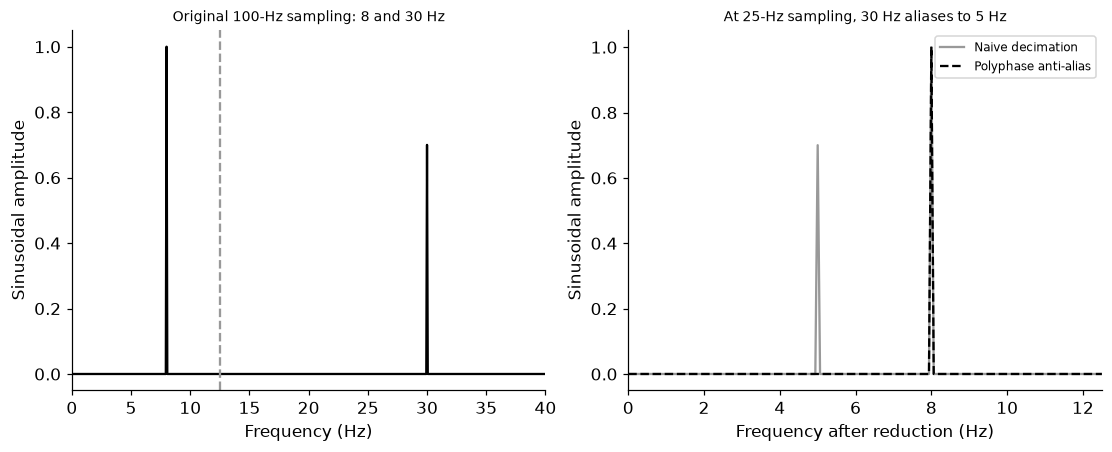

In [2]:
from scipy.signal import resample_poly
from scipy.stats import kstest
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import PoissonRegressor
fs=100.;seconds=20;time_signal=np.arange(int(fs*seconds))/fs;vibration=np.sin(2*np.pi*8*time_signal)+.7*np.sin(2*np.pi*30*time_signal);naive=vibration[::4];filtered=resample_poly(vibration,1,4,padtype='constant');new_fs=25.;trim=50
def spectrum(values,sample_rate):return np.fft.rfftfreq(len(values),1/sample_rate),2*np.abs(np.fft.rfft(values))/len(values)
original_frequency,original_amplitude=spectrum(vibration[200:-200],fs);frequency,naive_amplitude=spectrum(naive[trim:-trim],new_fs);_,filtered_amplitude=spectrum(filtered[trim:-trim],new_fs);at5=int(np.argmin(np.abs(frequency-5)));at8=int(np.argmin(np.abs(frequency-8)));assert abs(naive_amplitude[at5]-.7)<1e-10 and filtered_amplitude[at5]<.05 and filtered_amplitude[at8]>.9
sample_times=np.r_[0,np.sort(rng.uniform(0,10,99)),10];sample_values=np.sin(2*np.pi*.8*sample_times)+rng.normal(0,.03,len(sample_times));grid=np.arange(0,10,.05);offline=np.interp(grid,sample_times,sample_values);previous=np.searchsorted(sample_times,grid,side='right')-1;held=sample_values[previous];truth=np.sin(2*np.pi*.8*grid);before=np.flatnonzero(sample_times<5)[-1];query=float((sample_times[before]+sample_times[before+1])/2);changed_values=sample_values.copy();changed_values[sample_times>query]+=10;query_previous=np.searchsorted(sample_times,query,side='right')-1;hold_difference=float(changed_values[query_previous]-sample_values[query_previous]);offline_difference=float(np.interp(query,sample_times,changed_values)-np.interp(query,sample_times,sample_values));assert hold_difference==0 and offline_difference>1
B,K=60,40;exposure=rng.uniform(.5,3,(B,K));load=rng.uniform(-1,1,(B,K));regime=rng.binomial(1,.3,(B,K));building_effect=rng.normal(0,.15,(B,1));true_rate=np.exp(-1+.8*load+.3*regime+building_effect);count=rng.poisson(true_rate*exposure);event_times=[];boundaries=[]
for b in range(B):
    edge=np.r_[0,np.cumsum(exposure[b])];events=np.concatenate([np.sort(rng.uniform(edge[k],edge[k+1],count[b,k])) for k in range(K)]);event_times.append(events);boundaries.append(edge);assert len(events)==count[b].sum() and np.all(np.diff(events)>=0)
raw=np.stack([load,regime],axis=-1);scaler=StandardScaler().fit(raw[:40].reshape(-1,2));x=scaler.transform(raw.reshape(-1,2));observed_rate=(count/exposure).ravel();weight=exposure.ravel();owner=np.repeat(np.arange(B),K);train=owner<40;dev=(owner>=40)&(owner<50);final=owner>=50;constant=float(count[:40].sum()/exposure[:40].sum());best=np.inf;candidates=[]
def process_nll(rate,counts,duration):return float(np.sum(rate*duration-counts*np.log(rate))/np.sum(duration))
for alpha in [0.,.1]:
    model=PoissonRegressor(alpha=alpha,max_iter=1000,tol=1e-10).fit(x[train],observed_rate[train],sample_weight=weight[train]);prediction=model.predict(x);score=process_nll(prediction[dev],count.ravel()[dev],weight[dev]);candidates.append({'alpha':alpha,'development_process_NLL_per_day':score,'iterations':int(model.n_iter_)})
    if score<best:best=score;selected=model;selected_alpha=alpha
prediction=selected.predict(x).reshape(B,K);assert abs(float(count[:40].sum()-np.sum(prediction[:40]*exposure[:40])))<1e-4;rows=[];rescaled={};tails={}
for name,rate in [('Constant rate',np.full((B,K),constant)),('Covariate intensity',prediction)]:
    final_nll=process_nll(rate[50:],count[50:],exposure[50:]);probability=-np.expm1(-rate[50:]*exposure[50:]);binary=(count[50:]>0).astype(float);gaps=[];censored_tail=[]
    for b in range(50,60):
        edge=boundaries[b];events=event_times[b];cumulative=np.r_[0,np.cumsum(rate[b]*exposure[b])];interval=np.searchsorted(edge,events,side='right')-1;hazard_at_event=cumulative[interval]+rate[b,interval]*(events-edge[interval]);gaps.extend(np.diff(np.r_[0,hazard_at_event]));censored_tail.append(float(cumulative[-1]-(hazard_at_event[-1] if len(hazard_at_event) else 0)))
        event_log_likelihood=float(np.sum(np.log(rate[b,interval]))-cumulative[-1]);count_form=float(np.sum(count[b]*np.log(rate[b])-rate[b]*exposure[b]));np.testing.assert_allclose(event_log_likelihood,count_form,atol=1e-12)
    gaps=np.array(gaps);rescaled[name]=gaps;tails[name]=censored_tail;rows.append({'model':name,'final_process_NLL_per_day':final_nll,'final_any_event_Brier':float(np.mean((probability-binary)**2)),'completed_rescaled_gap_count':len(gaps),'rescaled_gap_mean':float(gaps.mean()),'rescaled_gap_Exp1_KS_statistic':float(kstest(gaps,'expon').statistic),'sum_right_censored_tail_hazard':float(np.sum(censored_tail))})
assert all(v>=0 for values in tails.values() for v in values)
RESULTS.update(signal_sampling={'original_Hz':fs,'reduced_Hz':new_fs,'original_components_Hz':[8,30],'aliased_30Hz_to':5.,'naive_5Hz_amplitude':float(naive_amplitude[at5]),'filtered_5Hz_amplitude':float(filtered_amplitude[at5]),'filtered_8Hz_amplitude':float(filtered_amplitude[at8]),'trimmed_boundary_seconds':trim/new_fs},irregular_signal={'sample_count':len(sample_times),'offline_interpolation_reference_MSE':float(np.mean((offline-truth)**2)),'causal_hold_reference_MSE':float(np.mean((held-truth)**2)),'future_perturbation_hold_change':hold_difference,'future_perturbation_offline_interpolation_change':offline_difference,'query_time':query},alarm_assessment=rows,candidates=candidates,selected_alpha=selected_alpha,constant_training_events_per_day=constant,split_buildings=[40,10,10],intervals_per_building=K,final_event_count=int(count[50:].sum()),final_exposure_days=float(exposure[50:].sum()),intensity_coefficients=selected.coef_.tolist(),intensity_intercept=float(selected.intercept_),complete_recording_assumed=True,right_censored_end_included_in_likelihood=True);display(pd.DataFrame(rows));display(pd.DataFrame(candidates))
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].plot(original_frequency,original_amplitude,color='black');axes[0].set(xlim=(0,40),xlabel='Frequency (Hz)',ylabel='Sinusoidal amplitude',title='Original 100-Hz sampling: 8 and 30 Hz');axes[0].axvline(12.5,color='.6',linestyle='--')
axes[1].plot(frequency,naive_amplitude,'-',color='.6',label='Naive decimation');axes[1].plot(frequency,filtered_amplitude,'--',color='black',label='Polyphase anti-alias');axes[1].set(xlim=(0,12.5),xlabel='Frequency after reduction (Hz)',ylabel='Sinusoidal amplitude',title='At 25-Hz sampling, 30 Hz aliases to 5 Hz');axes[1].legend(fontsize=8);plt.show()


<a id="signal-event-limits"></a>
 ## Availability and event exposure determine the likelihood
 Polyphase resampling is a zero-phase completed-window operation here and can use later signal samples; it is not advertised as a causal online filter. Boundary padding and trimmed evaluation are explicit. Offline interpolation likewise uses a future bracket, while previous hold is causal but can have larger reconstruction error. Neither reconstruction score forecasts an unobserved future waveform. Alarm intensity has units events/day. Fitting count/exposure with exposure weights gives the Poisson process likelihood up to model-independent terms and normalization; raw counts without exposure answer a different question. The event-time likelihood includes integrated hazard through the recording endpoint, including the right-censored tail after the last event. That tail is omitted only from complete-gap diagnostics, not from the fit/score. Correctly specified intensity would yield unit-exponential rescaled gaps under its assumptions; these fitted finite-sample KS statistics are descriptive, with no naive significance claim. Building-specific omitted effects intentionally permit residual intensity mismatch.


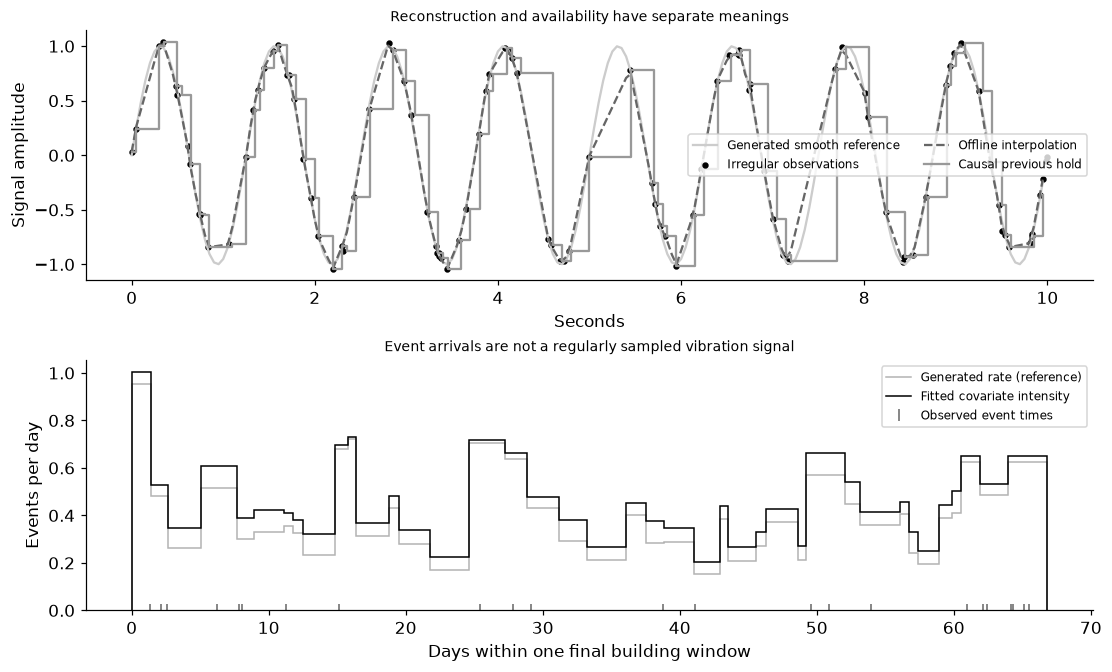

In [3]:
fig,axes=plt.subplots(2,1,figsize=(10,6));axes[0].plot(grid,truth,color='.8',label='Generated smooth reference');axes[0].scatter(sample_times,sample_values,s=10,color='black',label='Irregular observations');axes[0].plot(grid,offline,'--',color='.4',label='Offline interpolation');axes[0].step(grid,held,where='post',color='.6',label='Causal previous hold');axes[0].set(xlabel='Seconds',ylabel='Signal amplitude',title='Reconstruction and availability have separate meanings');axes[0].legend(fontsize=8,ncol=2)
b=50;edge=boundaries[b];axes[1].stairs(true_rate[b],edge,color='.7',label='Generated rate (reference)');axes[1].stairs(prediction[b],edge,color='black',label='Fitted covariate intensity');axes[1].plot(event_times[b],np.zeros(len(event_times[b])),'|',color='.4',markersize=8,label='Observed event times');axes[1].set(xlabel='Days within one final building window',ylabel='Events per day',title='Event arrivals are not a regularly sampled vibration signal');axes[1].legend(fontsize=8);plt.show()
assert all(np.isfinite(r['final_process_NLL_per_day']) for r in rows)


In [4]:
summary={'example_id':'code_124','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual polyphase anti-alias filtering', 'offline interpolation versus causal previous hold', 'exposure-weighted Poisson intensity fit', 'actual event-time likelihood with censored tail', 'time-rescaled event-gap diagnostics'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual polyphase anti-alias filtering", "offline interpolation versus causal previous hold", "exposure-weighted Poisson intensity fit", "actual event-time likelihood with censored tail", "time-rescaled event-gap diagnostics"], "elapsed_seconds": 1.244, "example_id": "code_124", "hardware": "Darwin arm64 CPU", "results": {"alarm_assessment": [{"completed_rescaled_gap_count": 311, "final_any_event_Brier": 0.22745929481914687, "final_process_NLL_per_day": 0.7962200588278789, "model": "Constant rate", "rescaled_gap_Exp1_KS_statistic": 0.05797668109230572, "rescaled_gap_mean": 1.0077815085540553, "sum_right_censored_tail_hazard": 18.020079262557527}, {"completed_rescaled_gap_count": 311, "final_any_event_Brier": 0.1935614512073748, "final_process_NLL_per_day": 0.738275417259188, "model": "Covariate intensity", "rescaled_gap_Exp1_KS_statistic": 0.029981476786988814, "rescaled_gap_mean": 1.0281562395154265, "sum_right_censored_tail_hazard": 2